Based on https://www.kaggle.com/datasets/vishala28/swat-dataset-secure-water-treatment-system?select=normal.csv

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ruptures as rpt
import numpy as np


In [2]:
# Specify the path to the dataset
DATA_PATH = "normal.csv"

In [3]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

df

,Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
0,28/12/2015 10:00:00 AM,2.427057,522.8467,2.0,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.5988,0.000128,1,1,1,Normal
1,28/12/2015 10:00:01 AM,2.446274,522.8860,2.0,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.6789,0.000128,1,1,1,Normal
2,28/12/2015 10:00:02 AM,2.489191,522.8467,2.0,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6789,0.000128,1,1,1,Normal
3,28/12/2015 10:00:03 AM,2.534350,522.9645,2.0,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6148,0.000128,1,1,1,Normal
4,28/12/2015 10:00:04 AM,2.569260,523.4748,2.0,2,1,262.0161,8.394514,328.6337,2.443085,...,2,1,250.8812,1.649953,189.5027,0.000128,1,1,1,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1387093,28/12/2015 9:59:55 AM,2.460366,523.0430,NaN,2,1,NaN,8.396437,328.5055,2.442316,...,2,1,250.8171,1.778105,189.8552,0.000128,1,1,1,Normal
1387094,28/12/2015 9:59:56 AM,2.448836,522.9645,NaN,2,1,NaN,8.396437,328.5055,2.442316,...,2,1,250.8171,1.778105,189.5027,0.000128,1,1,1,Normal
1387095,28/12/2015 9:59:57 AM,2.434744,522.8860,NaN,2,1,NaN,8.396437,328.6337,2.444879,...,2,1,250.8171,1.778105,189.5027,0.000128,1,1,1,Normal
1387096,28/12/2015 9:59:58 AM,2.428338,522.9252,NaN,2,1,NaN,8.396437,328.6337,2.445391,...,2,1,250.8171,1.649953,189.5027,0.000128,1,1,1,Normal


In [4]:
# Isolate pump 1 at stage 1

pump1_data = df['P101']
pump1_data.isnull().sum()

0

In [5]:
# downsample pump1_data to every 10th value to reduce noise and make change point detection more effective
pump1_data = pump1_data[::10].reset_index(drop=True)
pump1_data

0         2
1         2
2         2
3         2
4         2
         ..
138705    2
138706    2
138707    2
138708    2
138709    2
Name: P101, Length: 138710, dtype: int64

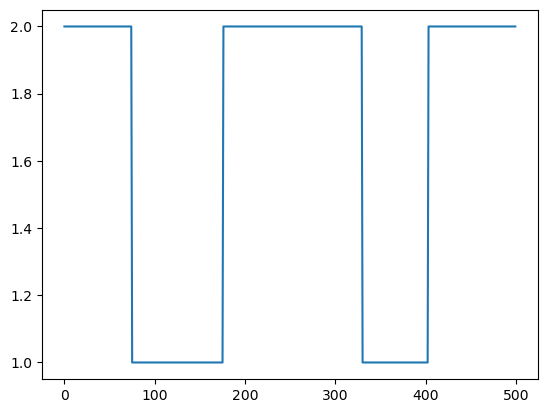

In [6]:
# plot first 500 values of pump1_data
sample_size = 500

plt.plot(pump1_data.head(sample_size))
plt.show()

In [7]:

    
# 2. Configure PELT
# 'l2' (Least Squares) is best for shifts in the mean
algo = rpt.Pelt(model="l2", jump=1).fit(pump1_data.head(sample_size).values)

# 3. Predict change points
# The 'pen' value is the sensitivity. 
result = algo.predict(pen=1.5)

result

[75, 176, 330, 403, 500]

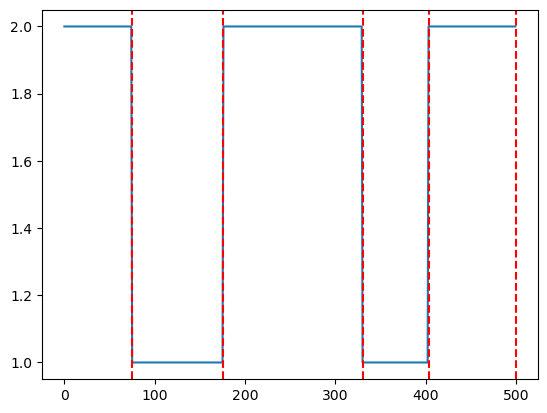

In [8]:
# plot results of change point detection onto the original signal

plt.plot(pump1_data.head(sample_size))
for res in result:
    plt.axvline(x=res, color='r', linestyle='--', label='Change Point')
plt.show()

In [ ]:
# 4. Calculate Dwell Times
change_points = [0] + result
dwell_times = np.diff(change_points)

print("Dwell Times:", dwell_times)

avg_dwell = float(np.mean(dwell_times))
avg_dwell

Dwell Times: [ 75 101 154  73  97]


100.0